In [37]:
pip install numpy

In [38]:
import pandas as pd
df = pd.read_csv(r"C:\Users\Pranav Hari\Documents\market_bars.csv")
df

C:\Users\Pranav Hari\AppData\Local\Temp\ipykernel_18292\1978247117.py:2: DtypeWarning: Columns (10,11,30,37,40) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r"C:\Users\Pranav Hari\Documents\market_bars.csv")


,instrument_id,source,source_symbol,asset_class,exchange,bar_interval,source_bar_interval,aggregation_source,aggregation_version,bar_origin,...,coverage_ratio,open_source,close_source,range_is_partial,volume_is_partial,quality_status,quality_flags,latest_source_retrieved_at_utc,generated_at_utc,backfilled_at_utc
0,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,derived_complete,...,1.0,observed,observed,False,False,pass,NaN,2026-09-18 05:17:10.366610+00:00,2026-09-18 05:18:15.830561+00:00,NaN
1,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,derived_complete,...,1.0,observed,observed,False,False,pass,NaN,2026-09-18 05:17:10.366610+00:00,2026-09-18 05:18:15.830561+00:00,NaN
2,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,derived_complete,...,1.0,observed,observed,False,False,pass,NaN,2026-09-18 05:17:10.366610+00:00,2026-09-18 05:18:15.830561+00:00,NaN
3,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,derived_complete,...,1.0,observed,observed,False,False,pass,NaN,2026-09-18 05:17:10.366610+00:00,2026-09-18 05:18:15.830561+00:00,NaN
4,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,derived_complete,...,1.0,observed,observed,False,False,pass,NaN,2026-09-18 05:17:10.366610+00:00,2026-09-18 05:18:15.830561+00:00,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72631,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,derived_complete,...,1.0,observed,observed,False,False,pass,NaN,2026-09-18 05:17:10.366610+00:00,2026-09-18 05:18:15.830561+00:00,NaN
72632,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,derived_complete,...,1.0,observed,observed,False,False,pass,NaN,2026-09-18 05:17:10.366610+00:00,2026-09-18 05:18:15.830561+00:00,NaN
72633,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,derived_complete,...,1.0,observed,observed,False,False,pass,NaN,2026-09-18 05:17:10.366610+00:00,2026-09-18 05:18:15.830561+00:00,NaN
72634,btc_usdt,binance_spot,BTCUSDT,crypto_spot,BINANCE,30m,5m,derived_from_5m,v1,derived_complete,...,1.0,observed,observed,False,False,pass,NaN,2026-09-18 05:17:10.366610+00:00,2026-09-18 05:18:15.830561+00:00,NaN


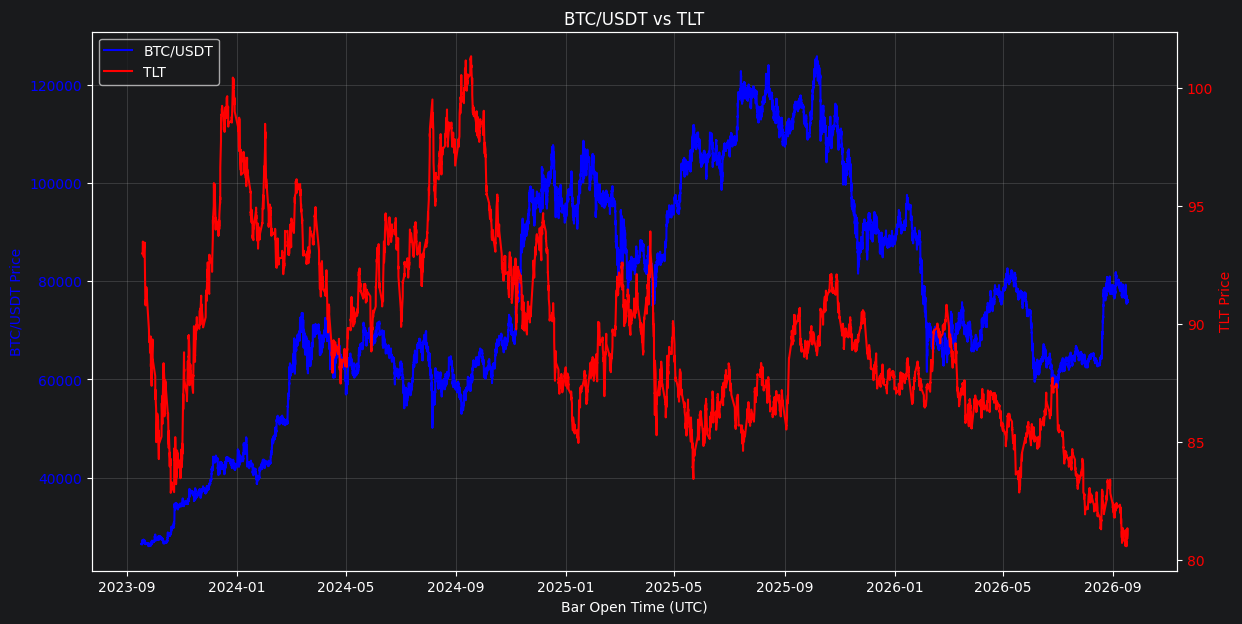

In [39]:
#simple plot of BTC/USD and TLT

import matplotlib.pyplot as plt

df["bar_open_time_utc"] = pd.to_datetime(df["bar_open_time_utc"])

# Calculate mid price
df["mid_price"] = (df["high"] + df["low"]) / 2

# Select BTC/USDT and TLT
btc = df[df["source_symbol"] == "BTCUSDT"].copy()
tlt = df[df["source_symbol"] == "TLT"].copy()

# Sort by time
btc = btc.sort_values("bar_open_time_utc")
tlt = tlt.sort_values("bar_open_time_utc")

# Create figure
fig, ax1 = plt.subplots(figsize=(14, 7))

# BTC — left y-axis
ax1.plot(
    btc["bar_open_time_utc"],
    btc["mid_price"],
    label="BTC/USDT",
    color="blue"
)

ax1.set_xlabel("Bar Open Time (UTC)")
ax1.set_ylabel("BTC/USDT Price", color="blue")
ax1.tick_params(axis="y", labelcolor="blue")

# TLT — right y-axis
ax2 = ax1.twinx()

ax2.plot(
    tlt["bar_open_time_utc"],
    tlt["mid_price"],
    label="TLT",
    color="red"
)

ax2.set_ylabel("TLT Price", color="red")
ax2.tick_params(axis="y", labelcolor="red")

# Title
plt.title("BTC/USDT vs TLT")

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper left"
)

ax1.grid(True, alpha=0.3)

plt.show()

In [40]:
btc = btc[["bar_open_time_utc", "mid_price"]].rename(
    columns={"mid_price": "BTC"}
)

tlt = tlt[["bar_open_time_utc", "mid_price"]].rename(
    columns={"mid_price": "TLT"}
)

data = pd.merge(
    btc,
    tlt,
    on="bar_open_time_utc",
    how="inner"
)

data = data.sort_values("bar_open_time_utc")
data = data.set_index("bar_open_time_utc")
data

,BTC,TLT
bar_open_time_utc,,
2023-09-18 13:30:00+00:00,27262.760,93.00300
2023-09-18 14:00:00+00:00,27204.790,92.99500
2023-09-18 14:30:00+00:00,27255.040,93.01500
2023-09-18 15:00:00+00:00,27286.310,92.95000
2023-09-18 15:30:00+00:00,27305.040,93.07250
...,...,...
2026-09-16 17:30:00+00:00,75645.260,81.23500
2026-09-16 18:00:00+00:00,75929.595,81.36000
2026-09-16 18:30:00+00:00,75698.415,81.21975


In [41]:
import numpy as np
data["BTC_ret"] = np.log(data["BTC"]).diff()
data["TLT_ret"] = np.log(data["TLT"]).diff()

data = data.dropna()

C:\Users\Pranav Hari\AppData\Local\Temp\ipykernel_18292\1696076799.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["rolling_corr_5d"] = (


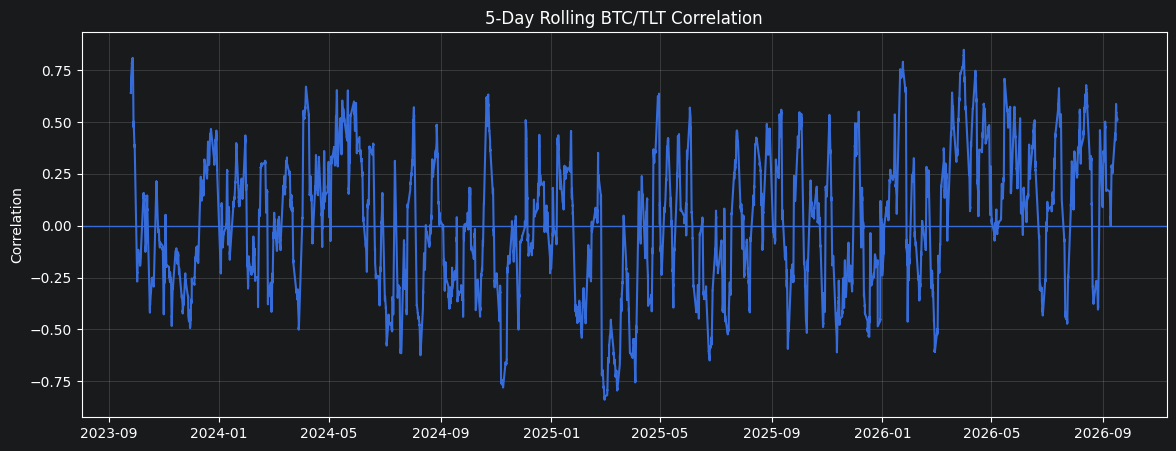

In [42]:

window = 13 * 5

data["rolling_corr_5d"] = (
    data["BTC_ret"]
    .rolling(window)
    .corr(data["TLT_ret"])
)
plt.figure(figsize=(14, 5))
plt.plot(
    data.index,
    data["rolling_corr_5d"]
)

plt.axhline(0, linewidth=1)

plt.title("5-Day Rolling BTC/TLT Correlation")
plt.ylabel("Correlation")
plt.grid(alpha=0.3)

plt.show()


In [43]:
import yfinance as yf
import pandas as pd
import numpy as np

vix = yf.download(
    "^VIX",
    start=data.index.min().strftime("%Y-%m-%d"),
    end=(data.index.max() + pd.Timedelta(days=1)).strftime("%Y-%m-%d"),
    interval="1d",
    auto_adjust=False,
    progress=False
)
vix = vix[("Close", "^VIX")].copy()
vix.name = "VIX"
vix_5d_change = vix.pct_change(5)

vix_lag = vix.shift(1)

vix_5d_change_lag = vix_5d_change.shift(1)
vix = pd.DataFrame({
    "VIX": vix,
    "VIX_5d_change": vix_5d_change,
    "VIX_lag": vix_lag,
    "VIX_5d_change_lag": vix_5d_change_lag
})

In [44]:
# Reset indexes so we can merge on timestamps
data_reset = data.reset_index()

# Make sure timestamps are datetime
data_reset["bar_open_time_utc"] = pd.to_datetime(
    data_reset["bar_open_time_utc"],
    utc=True
)

vix_reset = vix.reset_index()

vix_reset["Date"] = pd.to_datetime(
    vix_reset["Date"],
    utc=True
)

# Sort before merge_asof
data_reset = data_reset.sort_values("bar_open_time_utc")
vix_reset = vix_reset.sort_values("Date")

# Merge the latest available VIX observation
data_reset = pd.merge_asof(
    data_reset,
    vix_reset[
        ["Date", "VIX_lag", "VIX_5d_change_lag"]
    ],
    left_on="bar_open_time_utc",
    right_on="Date",
    direction="backward"
)

# Remove the extra Date column
data_reset = data_reset.drop(columns=["Date"])

# Restore timestamp as index
data = data_reset.set_index("bar_open_time_utc")

In [45]:
import yfinance as yf
import pandas as pd
import numpy as np

tnx_raw = yf.download(
    "^TNX",
    start=data.index.min().strftime("%Y-%m-%d"),
    end=(data.index.max() + pd.Timedelta(days=1)).strftime("%Y-%m-%d"),
    interval="1d",
    auto_adjust=False,
    progress=False
)

if isinstance(tnx_raw.columns, pd.MultiIndex):
    tnx = tnx_raw[("Close", "^TNX")].copy()
else:
    tnx = tnx_raw["Close"].copy()

# Convert ^TNX from e.g. 42.0 to 4.20%
tnx = tnx / 10
tnx.name = "10Y"

# Create all variables in a DataFrame
tnx = pd.DataFrame({
    "10Y": tnx,
    "10Y_5d_change": tnx.diff(5),
    "10Y_lag": tnx.shift(1),
    "10Y_5d_change_lag": tnx.diff(5).shift(1)
})

In [46]:
data_reset = data.reset_index()

data_reset["bar_open_time_utc"] = pd.to_datetime(
    data_reset["bar_open_time_utc"],
    utc=True
)

tnx_reset = tnx.reset_index()

tnx_reset["Date"] = pd.to_datetime(
    tnx_reset["Date"],
    utc=True
)

data_reset = data_reset.sort_values("bar_open_time_utc")
tnx_reset = tnx_reset.sort_values("Date")

data_reset = pd.merge_asof(
    data_reset,
    tnx_reset[
        ["Date", "10Y_lag", "10Y_5d_change_lag"]
    ],
    left_on="bar_open_time_utc",
    right_on="Date",
    direction="backward"
)

data_reset = data_reset.drop(columns=["Date"])

data = data_reset.set_index("bar_open_time_utc")

In [47]:
data["rate_regime"] = np.where(
    data["10Y_5d_change_lag"] > 0,
    "10Y rising",
    "10Y falling"
)

data["vol_regime"] = np.where(
    data["VIX_5d_change_lag"] > 0,
    "VIX rising",
    "VIX falling"
)

data["regime"] = (
    data["rate_regime"] + " / " + data["vol_regime"]
)
data

,BTC,TLT,BTC_ret,TLT_ret,rolling_corr_5d,VIX_lag,VIX_5d_change_lag,10Y_lag,10Y_5d_change_lag,rate_regime,vol_regime,regime
bar_open_time_utc,,,,,,,,,,,,
2023-09-18 14:00:00+00:00,27204.790,92.99500,-0.002129,-0.000086,NaN,NaN,NaN,NaN,NaN,10Y falling,VIX falling,10Y falling / VIX falling
2023-09-18 14:30:00+00:00,27255.040,93.01500,0.001845,0.000215,NaN,NaN,NaN,NaN,NaN,10Y falling,VIX falling,10Y falling / VIX falling
2023-09-18 15:00:00+00:00,27286.310,92.95000,0.001147,-0.000699,NaN,NaN,NaN,NaN,NaN,10Y falling,VIX falling,10Y falling / VIX falling
2023-09-18 15:30:00+00:00,27305.040,93.07250,0.000686,0.001317,NaN,NaN,NaN,NaN,NaN,10Y falling,VIX falling,10Y falling / VIX falling
2023-09-18 16:00:00+00:00,27253.945,93.18250,-0.001873,0.001181,NaN,NaN,NaN,NaN,NaN,10Y falling,VIX falling,10Y falling / VIX falling
...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-16 17:30:00+00:00,75645.260,81.23500,-0.001125,0.000677,0.510360,17.200001,0.094148,0.4996,0.019,10Y rising,VIX rising,10Y rising / VIX rising
2026-09-16 18:00:00+00:00,75929.595,81.36000,0.003752,0.001538,0.514966,17.200001,0.094148,0.4996,0.019,10Y rising,VIX rising,10Y rising / VIX rising
2026-09-16 18:30:00+00:00,75698.415,81.21975,-0.003049,-0.001725,0.516486,17.200001,0.094148,0.4996,0.019,10Y rising,VIX rising,10Y rising / VIX rising


In [48]:
data["regime"].value_counts()

regime
10Y rising / VIX rising      2815
10Y falling / VIX falling    2809
10Y rising / VIX falling     2263
10Y falling / VIX rising     1846
Name: count, dtype: int64

In [49]:
window = 13 * 30

rolling_cov = (
    data["BTC_ret"]
    .rolling(window)
    .cov(data["TLT_ret"])
)

rolling_var = (
    data["TLT_ret"]
    .rolling(window)
    .var()
)

data["beta"] = rolling_cov / rolling_var

In [50]:
data["beta_lag"] = data["beta"].shift(1)

data["residual"] = (
    data["BTC_ret"]
    - data["beta_lag"] * data["TLT_ret"]
)

In [51]:
resid_window = 13 * 30

data["resid_mean"] = (
    data["residual"]
    .rolling(resid_window)
    .mean()
    .shift(1)
)

data["resid_std"] = (
    data["residual"]
    .rolling(resid_window)
    .std()
    .shift(1)
)

data["resid_z"] = (
    (data["residual"] - data["resid_mean"])
    / data["resid_std"]
)

In [52]:
data["signal"] = 0

data.loc[data["resid_z"] > 2, "signal"] = -1
data.loc[data["resid_z"] < -2, "signal"] = 1

In [53]:
data["strategy_ret"] = (
    data["signal"].shift(1)
    * (
        data["BTC_ret"]
        - data["beta_lag"] * data["TLT_ret"]
    )
)

In [54]:
data["strategy_growth"] = (
    1 + data["strategy_ret"].fillna(0)
).cumprod()

In [55]:
data["strategy_growth"] = (
    1 + data["strategy_ret"].fillna(0)
).cumprod()

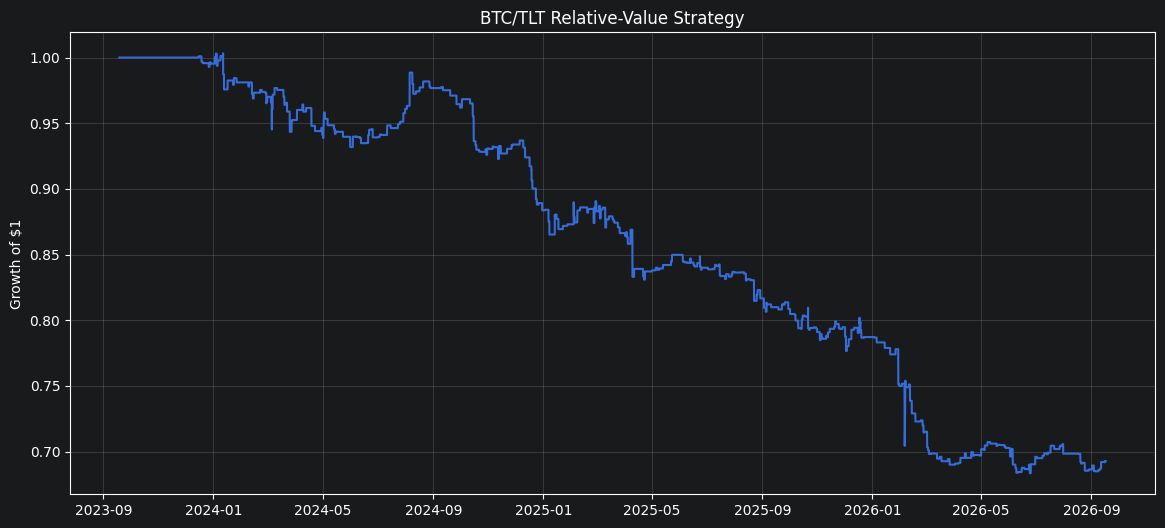

In [56]:
plt.figure(figsize=(14, 6))

plt.plot(
    data.index,
    data["strategy_growth"]
)

plt.title("BTC/TLT Relative-Value Strategy")
plt.ylabel("Growth of $1")
plt.grid(alpha=0.3)

plt.show()

In [57]:
regime_stats = (
    data
    .groupby("regime")["strategy_ret"]
    .agg(
        mean_return="mean",
        volatility="std",
        observations="count"
    )
)

regime_stats
regime_stats["hit_rate"] = (
    data
    .groupby("regime")["strategy_ret"]
    .apply(lambda x: (x > 0).mean())
)

regime_stats

,mean_return,volatility,observations,hit_rate
regime,,,,
10Y falling / VIX falling,-0.000048,0.001310,2666,0.014240
10Y falling / VIX rising,0.000042,0.002184,1820,0.018960
10Y rising / VIX falling,-0.000037,0.000980,2237,0.017234
10Y rising / VIX rising,-0.000085,0.001535,2620,0.017407


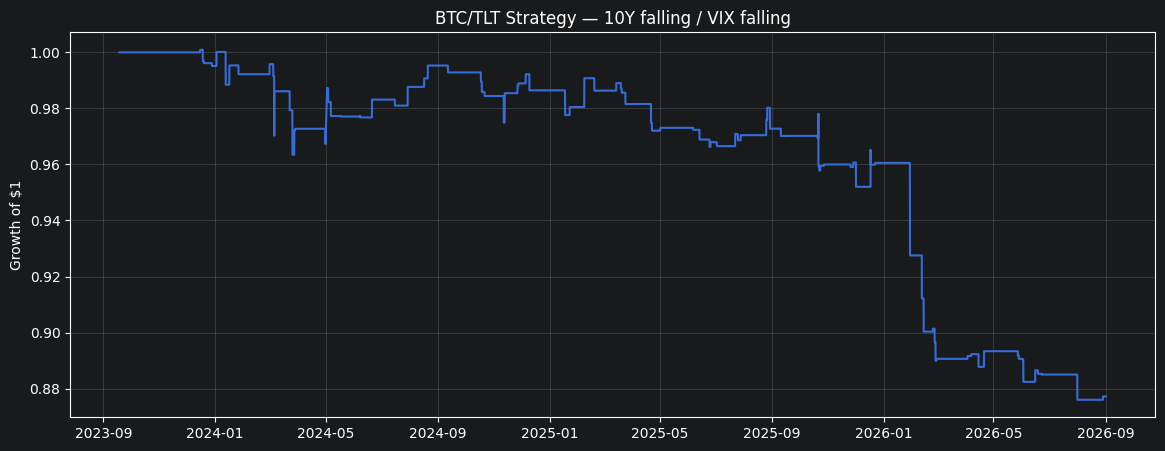

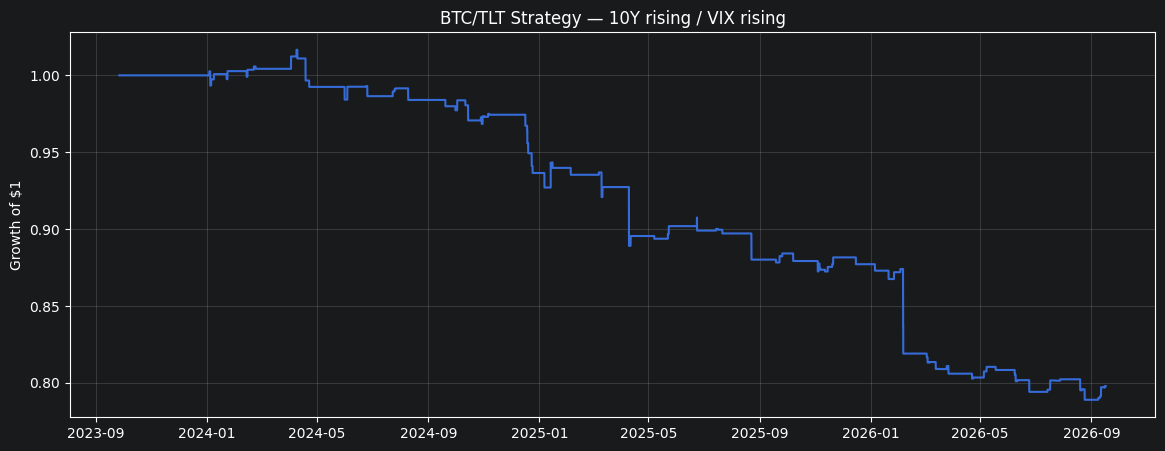

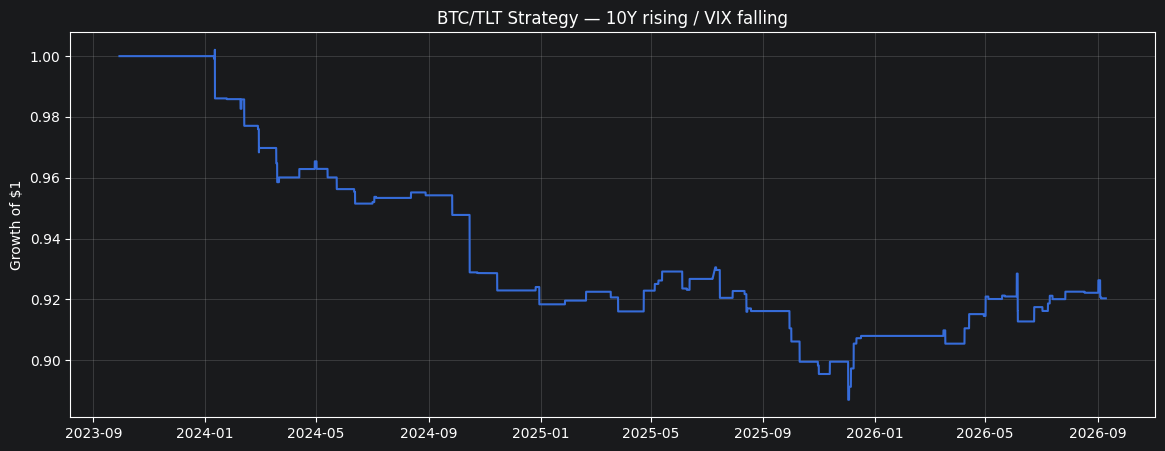

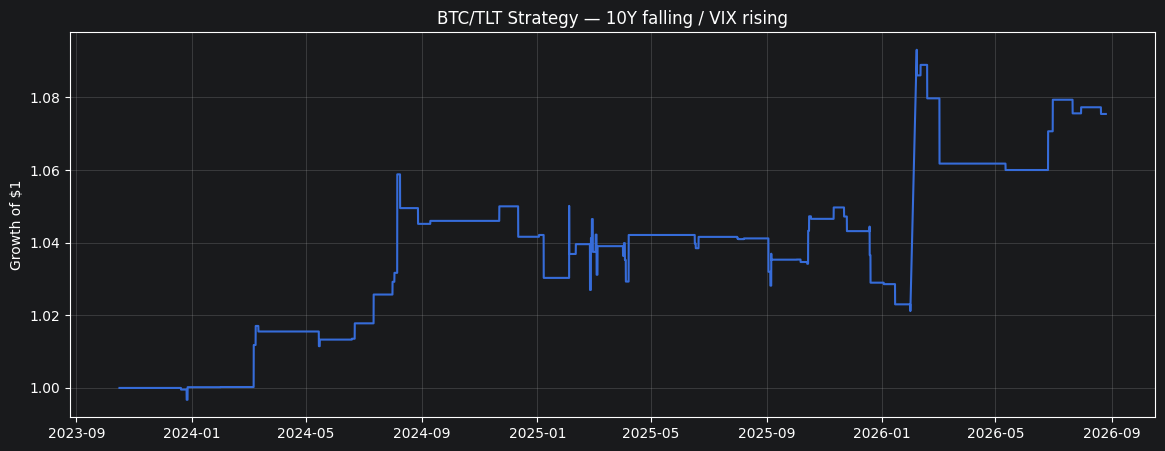

In [58]:
for regime in data["regime"].dropna().unique():

    temp = data[data["regime"] == regime].copy()

    temp["growth"] = (
        1 + temp["strategy_ret"].fillna(0)
    ).cumprod()

    plt.figure(figsize=(14, 5))

    plt.plot(
        temp.index,
        temp["growth"]
    )

    plt.title(f"BTC/TLT Strategy — {regime}")
    plt.ylabel("Growth of $1")
    plt.grid(alpha=0.3)

    plt.show()